# 01 · MLP Classifier (Tahap 1 Eksperimen Bagian 2)

**Tujuan:** melatih MLP Classifier **784 → 256 → 64 → 10** dengan **Cross-Entropy Loss** sampai akurasi test set **≥ 88%**, lalu menyimpan:
- bobot terlatih **W1, W2, W3**,
- fitur laten **z_MLP ∈ ℝ⁶⁴** (output lapisan sebelum klasifikasi akhir) untuk semua citra uji.

Notebook ini dijalankan **paling awal**, karena model classifier-nya juga dipakai notebook lain untuk mengecek *mode coverage* dan memilih titik interpolasi GAN.

> **Ide utama:** Cross-Entropy hanya "menyuruh" model **menebak kelas dengan benar**, yaitu memodelkan P(y | x). Detail yang tidak membantu menebak kelas, misalnya motif baju atau posisi lengan, tidak perlu dipertahankan. Akibatnya detail itu "dibuang" di sepanjang lapisan. Ini nanti dibuktikan di notebook 08.

In [2]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


## 1. Load Dataset

In [3]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [4]:
HIDDEN_DIMS = (256, 64)      # sama dengan encoder Autoencoder (784 -> 256 -> 64)
N_CLASSES = 10
LEARNING_RATE = 1e-3
MAX_EPOCHS = 2 if QUICK else 60
TARGET_ACC = 0.88

## 3. Model

```
x (784) --W1--> ReLU (256) --W2--> ReLU = z_MLP (64) --W3--> logits (10)
```

In [5]:
class MLPClassifier(nn.Module):
    def __init__(self, hidden=(256, 64), n_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(IMG_SIZE, hidden[0])    # W1: (256 x 784)
        self.fc2 = nn.Linear(hidden[0], hidden[1])   # W2: (64 x 256)
        self.fc3 = nn.Linear(hidden[1], n_classes)   # W3: (10 x 64)

    def features(self, x):
        # z_MLP: representasi laten sebelum lapisan klasifikasi akhir
        h1 = F.relu(self.fc1(x.flatten(1)))
        return F.relu(self.fc2(h1))

    def forward(self, x):
        return self.fc3(self.features(x))

model = MLPClassifier(HIDDEN_DIMS, N_CLASSES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print("Jumlah parameter:", count_params(model))

MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)
Jumlah parameter: 218058


## 4. Loss Function

**Cross-Entropy:** L = −(1/B) Σ log softmax(f(x))_y

In [6]:
@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
        total += len(y)
    return correct / total

## 5. Training (berhenti otomatis bila sudah ≥ 88% dan akurasi validasi tidak naik lagi selama 5 epoch)

In [7]:
history = {"model": "mlp_classifier", "params": count_params(model), "epoch": [], "iter_loss": [],
           "epoch_time_s": [], "train": [], "val": []}
best_val, best_state, best_epoch = -1, None, 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    t0 = time.perf_counter()
    total_loss, correct, seen = 0.0, 0, 0
    for it, (x, y) in enumerate(loaders["train"]):
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        seen += len(y)
        if it % 10 == 0:
            history["iter_loss"].append(loss.item())
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    val_acc = accuracy(model, loaders["val"])
    history["epoch"].append(epoch)
    history["train"].append({"loss": total_loss / seen, "acc": correct / seen})
    history["val"].append({"acc": val_acc})
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] Loss: {total_loss / seen:.4f}  Train Acc: {correct / seen:.4f}  Val Acc: {val_acc:.4f}")

    if val_acc > best_val:
        best_val, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())
    if val_acc >= TARGET_ACC + 0.005 and epoch - best_epoch >= 5:
        print("Berhenti: target tercapai dan akurasi validasi tidak naik lagi.")
        break

model.load_state_dict(best_state)
test_acc = accuracy(model, loaders["test"])
history["test_acc"] = test_acc
print(f"\nTEST ACCURACY = {test_acc:.4f}  ->  {'MEMENUHI' if test_acc >= TARGET_ACC else 'BELUM memenuhi'} target 88%")

Epoch[1/60] Loss: 0.5937  Train Acc: 0.7924  Val Acc: 0.8333
Epoch[2/60] Loss: 0.4107  Train Acc: 0.8545  Val Acc: 0.8591
Epoch[3/60] Loss: 0.3615  Train Acc: 0.8687  Val Acc: 0.8677
Epoch[4/60] Loss: 0.3380  Train Acc: 0.8770  Val Acc: 0.8627
Epoch[5/60] Loss: 0.3153  Train Acc: 0.8845  Val Acc: 0.8761
Epoch[6/60] Loss: 0.2971  Train Acc: 0.8908  Val Acc: 0.8761
Epoch[7/60] Loss: 0.2833  Train Acc: 0.8949  Val Acc: 0.8834
Epoch[8/60] Loss: 0.2752  Train Acc: 0.8972  Val Acc: 0.8800
Epoch[9/60] Loss: 0.2636  Train Acc: 0.9024  Val Acc: 0.8833
Epoch[10/60] Loss: 0.2524  Train Acc: 0.9065  Val Acc: 0.8877
Epoch[11/60] Loss: 0.2415  Train Acc: 0.9094  Val Acc: 0.8856
Epoch[12/60] Loss: 0.2341  Train Acc: 0.9129  Val Acc: 0.8871
Epoch[13/60] Loss: 0.2256  Train Acc: 0.9164  Val Acc: 0.8863
Epoch[14/60] Loss: 0.2179  Train Acc: 0.9182  Val Acc: 0.8959
Epoch[15/60] Loss: 0.2085  Train Acc: 0.9218  Val Acc: 0.8936
Epoch[16/60] Loss: 0.2029  Train Acc: 0.9243  Val Acc: 0.8936
Epoch[17/60] Loss

## 6. Plot Loss & Akurasi

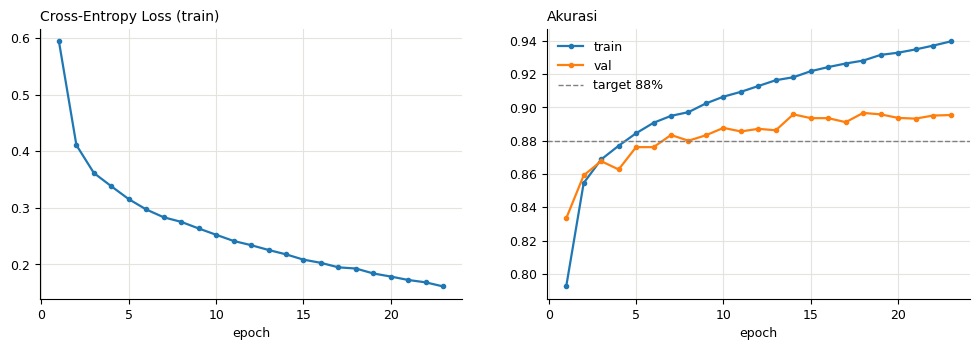

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(history["epoch"], [e["loss"] for e in history["train"]], "-o", ms=3)
axes[0].set_title("Cross-Entropy Loss (train)", loc="left"); axes[0].set_xlabel("epoch")
axes[1].plot(history["epoch"], [e["acc"] for e in history["train"]], "-o", ms=3, label="train")
axes[1].plot(history["epoch"], [e["acc"] for e in history["val"]], "-o", ms=3, label="val")
axes[1].axhline(TARGET_ACC, color="gray", ls="--", lw=1, label="target 88%")
axes[1].set_title("Akurasi", loc="left"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.show()

## 7. Simpan Bobot W1, W2, W3 dan Fitur Laten z_MLP

- `mlp_classifier.pt`: state_dict, dipakai notebook 08.
- `mlp_classifier_traced.pt`: versi TorchScript, supaya notebook lain bisa memakai classifier ini **tanpa** harus menulis ulang class-nya.

In [9]:
model.eval()
W1, W2, W3 = model.fc1.weight.detach().cpu(), model.fc2.weight.detach().cpu(), model.fc3.weight.detach().cpu()
print("W1:", tuple(W1.shape), "| W2:", tuple(W2.shape), "| W3:", tuple(W3.shape))

z_mlp = apply_batched(model.features, x_test)
print("z_MLP test:", tuple(z_mlp.shape))

torch.save({"model": model.state_dict(), "test_acc": test_acc}, CKPT_DIR / "mlp_classifier.pt")
traced = torch.jit.trace(model, torch.zeros(1, *IMG_SHAPE, device=device))
traced.save(str(CKPT_DIR / "mlp_classifier_traced.pt"))

save_results("mlp_classifier",
             {"model": "mlp_classifier", "test_acc": test_acc, "params": count_params(model),
              "target_reached": test_acc >= TARGET_ACC,
              "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"])),
              "hparams": {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "batch_size": BATCH_SIZE}},
             artifacts={"W1": W1, "W2": W2, "W3": W3, "z_mlp_test": z_mlp, "y_test": y_test},
             history=history)

W1: (256, 784) | W2: (64, 256) | W3: (10, 64)
z_MLP test: (7000, 64)
Hasil 'mlp_classifier' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
